# Parts 1–3 — CNN, ViT and self-supervised results, ablations, training curves, CKA

Everything here is read from `experiments/*/` (written by `scripts/train.py`, `scripts/ssl_frozen.py`,
`scripts/dino_adapt.py`); predictions and their verdicts are in `HYPOTHESES.md` (Blocks 1–3, S, H2.7, H2.8).
Site-grouped 5-fold CV EMD, mean ± std over folds; seed-to-seed noise is ≈ 0.2–0.7 (replicates), so
differences below ~2 are not effects.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from soilgs import paths
from soilgs.experiment import results_table

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
res = results_table()
res = res[~res.name.str.startswith(("smoke", "final_", "cka_"))]

def block(prefix, keep=None):
    t = res[res.name.str.startswith(prefix)].sort_values("cv_mean")
    if keep is not None:
        t = t[t.name.str.contains(keep)]
    return t[["name", "cv_mean", "cv_std", "gpu_hours", "peak_mem_gb", "device"]].round(3).reset_index(drop=True)

def history(name):
    return pd.read_csv(paths.EXPERIMENTS / name / "history.csv").groupby("epoch")[["train_loss", "val_emd"]].mean()

## Part 1 — CNNs: architectures × optimisation setups (ablation)

In [2]:
display(block("p1_"))

,name,cv_mean,cv_std,gpu_hours,peak_mem_gb,device
0,p1_r18_sgd,37.907,15.091,0.094,0.616,NVIDIA GeForce RTX 5070 Laptop GPU
1,p1_r18_gn,38.408,14.417,0.121,1.114,NVIDIA GeForce RTX 5070 Laptop GPU
2,p1_r18_scratch,39.323,14.553,0.178,0.655,NVIDIA L4
3,p1_r18_frozenbn_k2,39.714,15.345,0.090,0.658,NVIDIA GeForce RTX 5070 Laptop GPU
4,p1_r18_res112,41.730,15.734,0.061,0.331,NVIDIA GeForce RTX 5070 Laptop GPU
5,p1_r18_scaleaug,42.372,13.113,0.095,0.658,NVIDIA GeForce RTX 5070 Laptop GPU
6,p1_r18_blur,42.412,14.177,0.109,0.654,NVIDIA GeForce RTX 5070 Laptop GPU
7,p1_r18_noaug,43.280,15.281,0.097,0.658,NVIDIA GeForce RTX 5070 Laptop GPU
8,p1_r18_adamw_nested,43.875,15.246,0.434,0.750,NVIDIA A100-SXM4-40GB
9,p1_r18_color,43.964,15.378,0.096,0.658,NVIDIA GeForce RTX 5070 Laptop GPU


In [3]:
ABL = {"optimiser / schedule": ["p1_r18_adamw", "p1_r18_sgd", "p1_r18_adamw_nowarmup", "p1_r18_adamw_lr1e-3", "p1_r18_adamw_nested"],
       "BatchNorm with few samples per batch": ["p1_r18_adamw", "p1_r18_bn_k2", "p1_r18_frozenbn", "p1_r18_frozenbn_k2", "p1_r18_gn"],
       "augmentation": ["p1_r18_noaug", "p1_r18_adamw", "p1_r18_color", "p1_r18_scaleaug", "p1_r18_blur"],
       "input resolution / context": ["p1_r18_res112", "p1_r18_adamw", "p1_r18_tile100", "p1_r18_sgd", "p1_r18_sgd_ctx100"],
       "loss / pretraining": ["p1_r18_adamw", "p1_r18_sqrtmse", "p1_r18_scratch"],
       "architecture (AdamW recipe)": ["p1_r18_adamw", "p1_r50", "p1_effb0", "p1_convnext_t"]}
cv = res.set_index("name")
for title, names in ABL.items():
    names = [n for n in names if n in cv.index]
    print(f"— {title}:  " + " | ".join(f"{n.replace('p1_', '')} {cv.loc[n, 'cv_mean']:.1f}" for n in names))

— optimiser / schedule:  r18_adamw 45.7 | r18_sgd 37.9 | r18_adamw_nowarmup 44.3 | r18_adamw_lr1e-3 47.1 | r18_adamw_nested 43.9
— BatchNorm with few samples per batch:  r18_adamw 45.7 | r18_bn_k2 46.8 | r18_frozenbn 44.0 | r18_frozenbn_k2 39.7 | r18_gn 38.4
— augmentation:  r18_noaug 43.3 | r18_adamw 45.7 | r18_color 44.0 | r18_scaleaug 42.4 | r18_blur 42.4
— input resolution / context:  r18_res112 41.7 | r18_adamw 45.7 | r18_tile100 46.5 | r18_sgd 37.9
— loss / pretraining:  r18_adamw 45.7 | r18_sqrtmse 45.9 | r18_scratch 39.3
— architecture (AdamW recipe):  r18_adamw 45.7 | r50 45.0 | effb0 49.9 | convnext_t 46.5


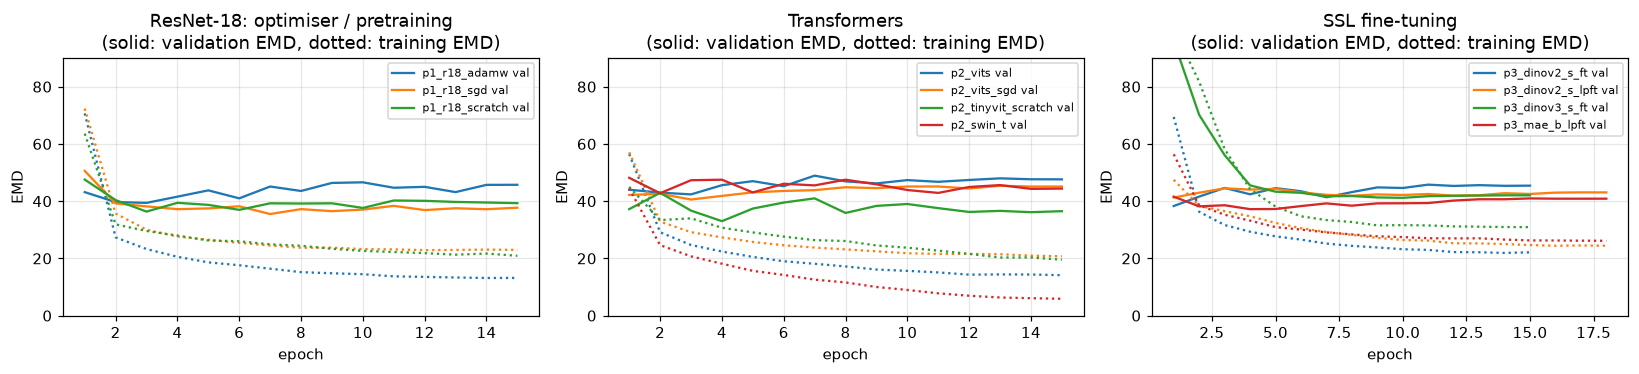

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, names, t in ((ax[0], ["p1_r18_adamw", "p1_r18_sgd", "p1_r18_scratch"], "ResNet-18: optimiser / pretraining"),
                    (ax[1], ["p2_vits", "p2_vits_sgd", "p2_tinyvit_scratch", "p2_swin_t"], "Transformers"),
                    (ax[2], ["p3_dinov2_s_ft", "p3_dinov2_s_lpft", "p3_dinov3_s_ft", "p3_mae_b_lpft"], "SSL fine-tuning")):
    for i, n in enumerate(names):
        if not (paths.EXPERIMENTS / n / "history.csv").exists():
            continue
        h = history(n)
        a.plot(h.index, h.val_emd, "-", color=f"C{i}", label=f"{n} val")
        a.plot(h.index, h.train_loss, ":", color=f"C{i}")
    a.set(title=t + "\n(solid: validation EMD, dotted: training EMD)", xlabel="epoch", ylabel="EMD", ylim=(0, 90)); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(paths.ROOT / "reports" / "fig_training_curves.png", dpi=110); plt.show()

## Part 2 — ViTs: from scratch → pretrained, optimisation ablation

In [5]:
display(block("p2_"))

,name,cv_mean,cv_std,gpu_hours,peak_mem_gb,device
0,p2_tinyvit_scratch,36.410,14.739,0.087,0.388,NVIDIA A100-SXM4-40GB
1,p2_tinyvit_scratch_nested,36.786,15.171,0.544,0.411,NVIDIA A100-SXM4-40GB
2,p2_tinyvit_scratch_p8,39.457,13.605,0.088,1.242,NVIDIA A100-SXM4-40GB
3,p2_vits_nested,39.588,14.932,0.697,1.718,NVIDIA A100-SXM4-40GB
4,p2_swin_t,44.347,16.658,0.264,2.799,NVIDIA A100-SXM4-40GB
5,p2_maxvit_t,44.520,16.126,0.375,3.134,NVIDIA A100-SXM4-40GB
6,p2_vits_sgd,45.081,16.911,0.203,1.442,NVIDIA A100-SXM4-40GB
7,p2_vits_384,45.663,17.628,0.277,2.072,NVIDIA A100-SXM4-40GB
8,p2_vits_nollrd,46.678,14.648,0.201,1.526,NVIDIA A100-SXM4-40GB
9,p2_vits_dp03,46.712,17.325,0.209,1.526,NVIDIA A100-SXM4-40GB


## Part 3 — Self-supervised encoders: frozen → LP → LP-FT → FT / LoRA, before and after domain adaptation

In [6]:
rows = []
for enc in ("dinov2_s", "dinov3_s", "mae_b"):
    r = {"encoder": enc}
    for col, name in (("frozen k-NN", f"p3_{enc}_frozen_knn"), ("frozen ridge", f"p3_{enc}_frozen_ridge"),
                      ("frozen ridge 100 mm", f"p3_{enc}_ctx100_frozen_ridge"), ("linear probe", f"p3_{enc}_lp"),
                      ("LP-FT", f"p3_{enc}_lpft"), ("full FT", f"p3_{enc}_ft"), ("LoRA r=8", f"p3_{enc}_lora8"),
                      ("FT 100 mm", f"p3_{enc}_ft_ctx100"), ("LP-FT 100 mm", f"p3_{enc}_lpft_ctx100")):
        r[col] = cv.loc[name, "cv_mean"] if name in cv.index else np.nan
    rows.append(r)
for tag in ("da_fixed", "da_rrc"):
    r = {"encoder": f"dinov2_s after DINO adaptation ({'scale-preserving views' if tag == 'da_fixed' else 'standard multi-crop'})"}
    for col, name in (("frozen k-NN", f"p3_dinov2_s_{tag}_frozen_knn"), ("frozen ridge", f"p3_dinov2_s_{tag}_frozen_ridge"),
                      ("linear probe", f"p3_dinov2_s_{tag}_lp"), ("LP-FT", f"p3_dinov2_s_{tag.replace('da_', 'da_')}_lpft")):
        r[col] = cv.loc[name, "cv_mean"] if name in cv.index else np.nan
    rows.append(r)
display(pd.DataFrame(rows).set_index("encoder").round(1))

,frozen k-NN,frozen ridge,frozen ridge 100 mm,linear probe,LP-FT,full FT,LoRA r=8,FT 100 mm,LP-FT 100 mm
encoder,,,,,,,,,
dinov2_s,52.4,49.0,42.3,61.0,43.1,45.5,46.6,NaN,NaN
dinov3_s,51.6,45.8,46.5,56.3,43.2,42.2,45.6,NaN,NaN
mae_b,43.6,45.1,44.3,62.7,40.9,46.9,NaN,NaN,NaN
dinov2_s after DINO adaptation (scale-preserving views),47.0,50.0,NaN,65.4,47.3,NaN,NaN,NaN,NaN
dinov2_s after DINO adaptation (standard multi-crop),46.9,48.9,NaN,63.0,46.6,NaN,NaN,NaN,NaN


### Domain adaptation run (continued DINO on unlabelled training tiles): training curves and cost

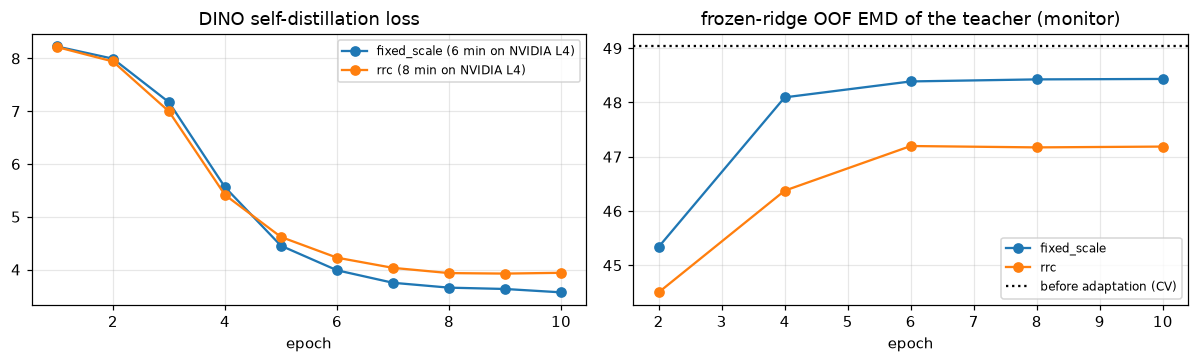

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for mode in ("fixed_scale", "rrc"):
    d = paths.EXPERIMENTS / f"p3_da_dinov2_s_{mode}"
    h = pd.read_csv(d / "history.csv")
    c = json.loads((d / "compute.json").read_text())
    ax[0].plot(h.epoch, h.dino_loss, "o-", label=f"{mode} ({c['hours'] * 60:.0f} min on {c['device']})")
    m = h.dropna(subset=["frozen_ridge_oof_emd"]) if "frozen_ridge_oof_emd" in h else h.iloc[:0]
    ax[1].plot(m.epoch, m.frozen_ridge_oof_emd, "o-", label=mode)
ax[0].set(title="DINO self-distillation loss", xlabel="epoch"); ax[0].legend(fontsize=8)
ax[1].axhline(cv.loc["p3_dinov2_s_frozen_ridge", "cv_mean"], color="k", ls=":", label="before adaptation (CV)")
ax[1].set(title="frozen-ridge OOF EMD of the teacher (monitor)", xlabel="epoch"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(paths.ROOT / "reports" / "fig_domain_adaptation.png", dpi=110); plt.show()

### CKA between the encoder before and after tuning (fold 0, 256 held-out tiles, per block)
Linear CKA of each transformer block's mean-token output: 1 = same representation up to rotation/scale.

/home/v.moisieiev/Documents/GitHub/cv_1_assignment/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,block 1,block 2,block 3,block 4,block 5,block 6,block 7,block 8,block 9,block 10,block 11,block 12
full FT,1.000,0.998,0.996,0.994,0.973,0.942,0.907,0.829,0.765,0.613,0.484,0.427
LP-FT,0.999,0.999,0.999,0.999,0.994,0.983,0.976,0.921,0.903,0.849,0.776,0.745
LoRA r=8,0.997,0.988,0.956,0.936,0.869,0.767,0.734,0.653,0.574,0.536,0.377,0.376


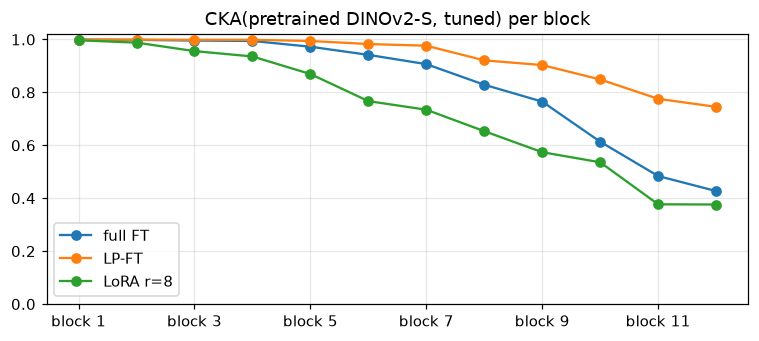

In [8]:
from soilgs.interpret import load_trained
from soilgs.ssl import cka_by_block, load_encoder
from soilgs.tiles import TARGET_PPM, tile_grid
from soilgs.train import Data, get_device

device = get_device()
data = Data.load()
fold0 = data.folds[data.folds.fold == 0].sample_id
t = int(round(50 * TARGET_PPM))
tiles = [data.images[p][y:y + t, x:x + t] for p in data.photos[data.photos.sample_id.isin(fold0) & (data.photos.split == "train")].photo_id
         for y, x, _ in tile_grid(*data.images[p].shape[:2], 50)]
tiles = np.stack(tiles[:: max(1, len(tiles) // 256)][:256])
base, mean, std = load_encoder("dinov2_s")
cka = {}
for label, name in (("full FT", "cka_dinov2_s_ft"), ("LP-FT", "cka_dinov2_s_lpft"), ("LoRA r=8", "cka_dinov2_s_lora8")):
    if not (paths.ROOT / "checkpoints" / name / "fold0.pt").exists():
        continue
    tuned, _, _, _ = load_trained(name, 0, device)
    cka[label] = cka_by_block(base, tuned.cpu(), tiles, mean, std, device)
    del tuned; torch.cuda.empty_cache()
cka = pd.DataFrame(cka, index=[f"block {i + 1}" for i in range(12)])
display(cka.round(3).T)
cka.plot(marker="o", figsize=(7, 3.2), title="CKA(pretrained DINOv2-S, tuned) per block", ylim=(0, 1.02))
plt.tight_layout(); plt.savefig(paths.ROOT / "reports" / "fig_cka.png", dpi=110); plt.show()